In [13]:
# imports

import numpy as np
import matplotlib.pyplot as plt
import rebound
import os
import argparse
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
%matplotlib inline
import time 

In [17]:
# constants from Dai 

M_A = 1.4         
M_B = 0.9        

R_IN = 5.9      
START_SEP_FACTOR = 10.0  # start integration at 10*R_peri separation (when A and B still weakly interacting) 

AU_PER_YR_TO_KMS = 4.74047 # conversion 

OBSERVED_AB_SEP_AU = 280

pa_rotation=0.0

# ALMA observation 
target_inc_deg=55.51
target_pa_deg=41.05
obs_sep=210.0
sigma_sep=20.0 # arbitrary tolerance 
obs_pa=254.14
sigma_pa=5.0 # arbitrary tolerance 

disc_fit_radius=30.0 # radius of inner disc to fit disc inclination

## set-up functions: running and plotting REBOUND sims

In [16]:
# All set-up functions 

def convert_omega(theta, phi):
    
    ''' i=theta, Omega=phi_pi/2  

    inputs: theta, phi
    outputs: i, Omega '''
    
    return theta, np.pi/2 + phi 

################################### build REBOUND sim with 2 stars 

def add_binary(sim, r_peri, ecc, peri_direction_deg):
    
    ''' make star A and star B REBOUND sim
    
    inputs: empty REBOUND simulation, radius of pericentre, eccentricity, pericentre direction
    outputs: star A and B REBOUND particle objects (3D position and velocity vectors and mass) '''
    
    m_a=M_A
    m_b=M_B
    start_sep_factor=START_SEP_FACTOR

    # simulate A (set starA as first item in sim)
    sim.add(m=m_a, name="A")
    starA = sim.particles[0] 

    # semi-major axis
    a = r_peri/(1-ecc) 
    # semi-latus rectum (useful to find r_peri)
    p = r_peri*(1+ecc)

    # where B starts 
    r_start = start_sep_factor*r_peri 

    # f: true anomaly (where B is along its orbit) corresponding to start distance 
    # f<0: start 
    # f=0: closest approach
    # f>0: after encounter
    cos_f = np.clip((p/r_start - 1)/ecc, -1.0, 1.0) 
    f_start = -np.arccos(cos_f)

    # simulate B around primary star A
    sim.add(m=m_b, a=a, e=ecc, inc=0.0, Omega=0.0, omega=np.radians(peri_direction_deg), 
            f=f_start, primary=starA, name="B")

    sim.move_to_com() # centre of mass frame (COM as origin)
    
    return sim.particles[0], sim.particles[1] 

## add disc particles around A

def add_disc(sim, primary, n_particles, r_out, theta_disc, phi_disc, seed):
    
    ''' add disc of massless particles around A between inner and outer disc with theta and phi tilt 
    
    inputs: REBOUND sim, number of particles, outer radius of disc, inclination of disc (theta, phi), 
    seed (randomness of positions) keeps every seed number the same composition
    
    outputs: REBOUND sim with disc particles around A, R initial radii of particles (array), 
    f initial true anomalies (array)  '''

    rng = np.random.default_rng(seed) # generates random numbers for particle positions
    
    inc, Omega = convert_omega(theta_disc, phi_disc)

    # random radii generation for each particle (between inner and outer disc boundaries)
    R = rng.uniform(R_IN, r_out, n_particles)
    # random true anomaly generation for each particle (spreads particles 360deg around star)
    f = rng.uniform(0, 2*np.pi, n_particles)

    # puts particles in index 
    primary_index = primary.index 
    for Ri, fi in zip(R, f):
        sim.add(m=0.0, a=Ri, e=0.0, inc=inc, Omega=Omega, omega=0.0, f=fi, primary=sim.particles[primary_index])

    return sim, R, f
    
## piecing the simulation together 

def build_simulation(n_disc, seed, r_out, theta_disc, phi_disc, r_peri, ecc, peri_direction_deg, integrator="ias15"):

    ''' create initial REBOUND model by combining the functions above 
    
    inputs: integrator (IAS15 is REBOUND's high-accuracy adaptive integrator)
    outputs: full initial REBOUND sim, R initial radii of particles (array), 
    f initial true anomalies (array)'''
    
    sim = rebound.Simulation() # create empty sim
    sim.G = 4*np.pi**2 # set grav constant G
    sim.integrator = integrator # numerical method used by REBOUND to evolve system

    # add star A and B to sim
    starA, _ = add_binary(sim, r_peri, ecc, peri_direction_deg)

    # add disc around A
    _, R0, f0 = add_disc(sim, starA, n_disc, r_out, theta_disc, phi_disc, seed)

    # ONLY FIRST 2 PARTICLES ARE MASSIVE GRAV BODIES
    sim.N_active = 2
    
    return sim, R0, f0

################################### find the pericentre 

def AB_relative_movement(sim):

    ''' calculate current A-B separation towards/away from each other
    
    outputs: A-B separation (magnitude of position vector), 
    r.v dot product (r.v<0: moving closer, r.v>0: moving farther away) '''
    
    A, B = sim.particles[0], sim.particles[1]

    # relative position and velocity vectors
    r = np.array([B.x-A.x, B.y-A.y, B.z-A.z])
    v = np.array([B.vx-A.vx, B.vy-A.vy, B.vz-A.vz])
    
    return np.linalg.norm(r), np.dot(r, v)

    
def pericentre_time(r_peri, ecc, peri_direction_deg):

    ''' finding the time of pericentre how long after the start of the sim
    
    output: time corresponding to the smallest A-B separation '''
    
    # creating and defining REBOUND sim with stars A and B
    sim = rebound.Simulation()
    sim.units = ("yr", "AU", "Msun")
    sim.integrator = "ias15"
    add_binary(sim, r_peri, ecc, peri_direction_deg)

    times = np.linspace(0, 5000, 5001) # array of times 0 to 5000 (ERROR: TEMPORAL RESOLUTION IS 1 YEAR)
    separations = [] # list to store AB separations at every year 

    # Loop through every time  (every year) to evolve A and B until t
    for t in times:

        # integrate until t and calculate separation and add to list 
        sim.integrate(t)
        sep, _ = AB_relative_movement(sim)
        separations.append(sep) 
        
    return times[np.argmin(separations)]

################################### sky projection 

# sky plane basis vectors 
def observer_basis(theta_obs, phi_obs, pa_rotation):
    
    ''' observer's coordinate system: east sky, north sky, line of sight direction
    
    outputs: 3 unit direction vectors '''
    
    theta_obs = np.pi - theta_obs # flip theta

    # line of sight (3D unit vector)
    los = np.array([np.sin(theta_obs)*np.cos(phi_obs),
                    np.sin(theta_obs)*np.sin(phi_obs),
                    np.cos(theta_obs)])
    # 2 directions perpendicular to line of sight 
    e_theta = np.array([np.cos(theta_obs)*np.cos(phi_obs), # theta direction
                        np.cos(theta_obs)*np.sin(phi_obs),
                        -np.sin(theta_obs)])
    e_phi = np.array([-np.sin(phi_obs), np.cos(phi_obs), 0.0]) # phi direction

    # rotate sky plane
    c = np.cos(pa_rotation)
    s = np.sin(pa_rotation)
    north = c*e_theta + s*e_phi
    east = c*e_phi - s*e_theta
    
    return east, north, los

## particle coordiantes in sky plane 
# position
def project_positions(rel_pos, theta_obs, phi_obs, pa_rotation):
    
    ''' convert 3D positions in the sim into observer east, north, los depth
    
    inputs: 3D position vectors, observer viewing angle and direction
    outputs: particle's coordinate on the sky '''

    # directions in original sim
    east, north, los = observer_basis(theta_obs, phi_obs, pa_rotation) 

    # dot product of 3D position vectors and basis vectors = coordinate in that direction
    return rel_pos@east, rel_pos@north, rel_pos@los

# velocity 
def project_velocities(rel_vel, theta_obs, phi_obs, pa_rotation):

    ''' convert particle's 3D velocity in sim into velocity component along observer's los 
    
    outputs: velocity component in km/s '''
    
    _, _, los = observer_basis(theta_obs, phi_obs, pa_rotation)
    
    # dot product of relative velocity and line of sight component (in km/s)
    return (rel_vel@los)*AU_PER_YR_TO_KMS

# ROTATION - CONSTRAINT: PA (relative position angle of B from A) 
def calibrate_pa_rotation(sim, theta_obs, phi_obs, target_AB_PA_deg):

    ''' find sky-plane rotation to match A-B observed PA 
    how much to rotate the projected view (theta_obs and phi_obs) to get observed PA 
    
    outputs: best fitted PA (in degrees) to observer basis, 
    final model AB PA (projected position angle onto the sky), 
    projected AB separation THAT WE WOULD SEE ON THE PLANE OF THE SKY (in AU) '''

    n_scan=720 # step size (360/720 = 0.5deg) ERROR: 0.5deg PA step 
    
    A, B = sim.particles[0], sim.particles[1] 
    rel = np.array([[B.x-A.x, B.y-A.y, B.z-A.z]]) # get B's position relative to A

    best_pa = 0 # store best PA found 
    best_diff = np.inf # stores diff between model PA and target PA 

    # trial rotations from 0 to 360deg 
    for pa_deg in np.linspace(0, 360, n_scan, endpoint=False):

        # coordinate basis for each PA
        east, north, _ = observer_basis(theta_obs, phi_obs, np.radians(pa_deg)) 
        # B's relative position 
        e, n = rel[0]@east, rel[0]@north # rel[0] is a x,y,z coordinates array

        # calculate postion angle of A relative to A
        pa_model = np.degrees(np.arctan2(e, n)) % 360
        diff = min(abs(pa_model-target_AB_PA_deg), 360-abs(pa_model-target_AB_PA_deg))
        # store smallest difference model PA from obs PA 
        if diff < best_diff:
            best_diff, best_pa = diff, pa_deg

    # coordiante system with best PA 
    east, north, _ = observer_basis(theta_obs, phi_obs, np.radians(best_pa))
    e, n = rel[0]@east, rel[0]@north

    return best_pa, np.degrees(np.arctan2(e, n)) % 360, np.hypot(e, n)

# rotate final frame 
def rotate_disc_to_observation(sim_final):

    ''' rotates entire final sim frame to align with observed disc inclination and position angle

    inputs: final REBOUND sim, obs disc inclination, obs disc PA, disc radius 
    outputs: final disc inclination, final disc PA, angle the sim has been rotated (in deg), 
    disc particles used to estimate disc orientation (index) '''

    # every particle's positions and velocities relative to A 
    A = sim_final.particles[0]
    pos = np.array([[p.x-A.x, p.y-A.y, p.z-A.z] for p in sim_final.particles])
    vel = np.array([[p.vx-A.vx, p.vy-A.vy, p.vz-A.vz] for p in sim_final.particles])

    # identify inner disc particles 
    idx = np.arange(2, len(pos)) # store 2 = disc particles
    idx = idx[np.linalg.norm(pos[idx], axis=1) < disc_fit_radius] # r<30AU (ERROR: disc inclination calibration particles up to 30AU)
    if len(idx) < 5:  # in case not enough particles in disc 
        raise ValueError(f"Only {len(idx)} tracers within {disc_fit_radius} AU of A.")

    # find current disc orientation 
    # L:individual angular momentum vectors of particles (array)
    # Lhat: average unit direction of all vectors 
    L = np.cross(pos[idx], vel[idx]) # find direction of disc normal (angular momentum points perpendicular to orbital plane)
    Ln = np.linalg.norm(L, axis=1) # magnitude of angular momentum vector for every particle 
    Lhat = np.mean(L[Ln>0]/Ln[Ln>0,None], axis=0) # average directions of every L vector 
    Lhat /= np.linalg.norm(Lhat) # make it a unit vector 
    if Lhat[2] < 0: Lhat = -Lhat # force it to point upwards (since Lhat and -Lhat same plane)

    # get target disc normals 
    inc, pa = np.radians([target_inc_deg, target_pa_deg]) # deg to rad
    # disc normal corresponding to target inc and PA (2 same inclinations +/-180deg)
    targets = [np.array([np.sin(inc)*np.cos(pa), -np.sin(inc)*np.sin(pa), np.cos(inc)]),
               np.array([-np.sin(inc)*np.cos(pa), np.sin(inc)*np.sin(pa), np.cos(inc)])] 

    # calculate rotation needed for every target disc normal 
    angles = [np.arccos(np.clip(np.dot(Lhat,t), -1, 1)) for t in targets] # angle between current and each target normal 
    angle = min(angles) # choose smallest rotation between the 2 (same) angles 
    target_L = targets[np.argmin(angles)] # the target normal to rotate to

    # find rotation axis 
    axis = np.cross(Lhat, target_L) # axis is perpendicular to Lcurrent and Ltarget 
    norm = np.linalg.norm(axis) # noramlize axis 

    # rotation matrix 
    if norm < 1e-12: # if current disc already aligned with target (eye is Identity matrix)
        R = np.eye(3)
    else: # get 3x3 matrix rotation around axis by angle 
        x, y, z = axis/norm # rotation axis unit vector 
        K = np.array([[0,-z,y], [z,0,-x], [-y,x,0]]) # skew-symmetric matrix 
        R = np.eye(3) + np.sin(angle)*K + (1-np.cos(angle))*(K@K) # Rodrigues' rotation formula

    # apply rot matrix to ALL particle positions 
    pos_rot = (R@pos.T).T
    vel_rot = (R@vel.T).T

    # final check: repeat disc-normal calculation 
    L = np.cross(pos_rot[idx], vel_rot[idx]) # rotated angular momenta 
    Ln = np.linalg.norm(L, axis=1) # magnitudes of L
    L = np.mean(L[Ln>0]/Ln[Ln>0,None], axis=0) # average disc normal 
    L /= np.linalg.norm(L)
    if L[2] < 0: # get positive z normal
        L = -L

    # calculate resulting inclination 
    final_inc = np.degrees(np.arccos(np.clip(L[2], -1, 1))) # should be around 55deg 
    major = np.cross([0,0,1], L) # line where disc plane intersects with sky plane (projected disc major axis)
    final_pa = np.degrees(np.arctan2(major[0], major[1])) % 180 # position angle of projected major axis 

    return pos_rot, vel_rot, {"inclination_after": final_inc, "pa_after": final_pa,
                              "disc_rotation_deg": np.degrees(angle), "disc_indices": idx}

################################### run the models (and get snapshots) 

def run_model(r_peri, r_out, theta_disc_deg, phi_disc_deg, ecc,
                        peri_direction_deg, t_final, n_disc, n_snapshots, seed=0):
    
    ''' get multiple snapshots spaced out in time for a given model
    
    outputs: snapshot(s) of model as a function of integrated time t (list) 
    for one snapshot, call the function with result = run_model(..., n_snapshots=1)[0] '''

    # array of times to make snapshots if not case of one snapshot
    times_after_peri = np.array([t_final]) if n_snapshots == 1 else np.linspace(0, t_final, n_snapshots)
    # time of pericentre 
    t_peri = pericentre_time(r_peri, ecc, peri_direction_deg)

    # build simulation 
    sim, R0, f0 = build_simulation(
        n_disc, seed, r_out, np.radians(theta_disc_deg), np.radians(phi_disc_deg),
        r_peri, ecc, peri_direction_deg
    )

    results = [] 
    
    # for every requested time: integrate snapshot at time t_peri+t_after, rotate the frame, extract particle coords
    for t_after in times_after_peri:

        sim.integrate(t_peri + t_after)

        # rotate model 
        pos_rot, vel_rot, rot = rotate_disc_to_observation(sim)
        # particle coords 
        east, north = pos_rot[2:, 0], pos_rot[2:, 1]
        # star B coords 
        east_B, north_B = pos_rot[1, 0], pos_rot[1, 1]

        results.append({
            "positions": pos_rot, "velocities": vel_rot,
            "east": east, "north": north, "east_B": east_B, "north_B": north_B,
            "R0": R0, "f0": f0,
            "sep_AU": np.hypot(east_B, north_B),
            "ab_pa_deg": np.degrees(np.arctan2(east_B, north_B)) % 360,
            "t_after_peri": t_after, "t_target": t_peri + t_after,
            "inc_after": rot["inclination_after"], "pa_after": rot["pa_after"],
            "disc_rotation_deg": rot["disc_rotation_deg"],
            "r_peri": r_peri, "r_out": r_out,
            "theta_disc_deg": theta_disc_deg, "phi_disc_deg": phi_disc_deg,
            "ecc": ecc, "peri_direction_deg": peri_direction_deg,
            "n_disc": n_disc, "seed": seed
        })

    return results

################################### plotting models 

def plot_models(results, max_cols=4):

    ''' plotting the models as outputs of REBOUND sims '''
    
    # converts results (outputs of run_model) into a list instead of dictionary
    if isinstance(results, dict): results = [results]

    # plot grid 
    n = len(results) # number of models 
    ncols = min(n, max_cols) # number of columns 
    nrows = int(np.ceil(n/ncols)) # number of rows 

    # plot figure (subplots)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows), squeeze=False)
    axes = axes.flatten() # 2D grid of axes into 1D list 

    # colouring particles according to initial radii (find boundaries of disc radius)
    r0_min = min(r["R0"].min() for r in results)
    r0_max = max(r["R0"].max() for r in results)

    # figure boundaries and position (to match ALMA obs)
    lim = 840 # (+/-840AU)
    au_per_arcsec = 140 # 1'' = 140AU # ERROR: arc sec to AU - assumption from Rodrigues (2018)
    # shift whole model to match obs
    x_shift = 2 * au_per_arcsec
    y_shift = -1 * au_per_arcsec
    # tick positions on axis
    major_ticks = [-560, 0, 560]
    minor_ticks = np.arange(-840, 841, 140)

    # loop through each subplot to match offset (to ALMA obs)
    for i, result in enumerate(results):
        ax = axes[i] 
        # projected particle coordinates + offset 
        east = result["east"] + x_shift
        north = result["north"] + y_shift
        # projected star B coordinates + offset 
        east_B = result["east_B"] + x_shift
        north_B = result["north_B"] + y_shift

        # plot disc particles 
        sc = ax.scatter(east, north, c=result["R0"], cmap="viridis", vmin=r0_min, vmax=r0_max, s=4, alpha=0.8, linewidths=0)
        
        # plot star A
        ax.scatter(x_shift, y_shift, marker="*", s=100, color="gold", edgecolor="black", zorder=10)

        # plot star B
        ax.scatter(east_B, north_B, marker="*", s=100, color="orange", edgecolor="black", zorder=10)

        ##axis
        # axis limits 
        ax.set_xlim(lim, -lim)
        ax.set_ylim(-lim, lim)
        # Labels only at ±4" and 0
        ax.set_xticks(major_ticks)
        ax.set_yticks(major_ticks)
        # Small markers every 1"
        ax.set_xticks(minor_ticks, minor=True)
        ax.set_yticks(minor_ticks, minor=True)
        ax.grid(which="major", alpha=0.15)
        ax.grid(which="minor", visible=False)
        ax.tick_params(which="major", length=5) # length of ticks 
        ax.tick_params(which="minor", length=2)

        # labels
        ax.set_aspect("equal") # equal 1AU in x and y axis 
        ax.set_xlabel("East (AU)")
        ax.set_ylabel("North (AU)")
        

        # subplot titles with parameters 
        ax.set_title(
            f"Rp={result['r_peri']:.0f}, Rout={result['r_out']:.0f}, θ={result['theta_disc_deg']:.0f}°\n"
            f"e={result['ecc']:.2f}, φ={result['phi_disc_deg']:.0f}°, t={result['t_after_peri']:.0f} yr\n"
            f"i={result['inc_after']:.1f}°, PA={result['pa_after']:.1f}°\n"
            f"AB={result['sep_AU']:.0f} AU, AB PA={result['ab_pa_deg']:.1f}°",
            fontsize=9
        )
        
    # hides unused spaces 
    for ax in axes[n:]: ax.axis("off")

    # legend colourbar 
    fig.colorbar(sc, ax=axes[:n].tolist(), label="Initial disc radius (AU)", shrink=0.8)

    plt.show()

In [22]:
# rotate final frame 
def rotate_disc_to_observation(sim_final):

    ''' rotates entire final sim frame to align with observed disc inclination and position angle

    inputs: final REBOUND sim, obs disc inclination, obs disc PA, disc radius 
    outputs: final disc inclination, final disc PA, angle the sim has been rotated (in deg), 
    disc particles used to estimate disc orientation (index) '''

    # every particle's positions and velocities relative to A 
    A = sim_final.particles[0]
    pos = np.array([[p.x-A.x, p.y-A.y, p.z-A.z] for p in sim_final.particles])
    vel = np.array([[p.vx-A.vx, p.vy-A.vy, p.vz-A.vz] for p in sim_final.particles])

    theta_obs = np.radians(76.0)
    phi_obs = np.radians(114.0)
    
    pa_deg, _, _ = calibrate_pa_rotation(sim_final, theta_obs, phi_obs, obs_pa)
    
    pa_rad = np.radians(pa_deg)
    
    east, north, los = project_positions(pos, theta_obs, phi_obs, pa_rad)
    veast, vnorth, vlos = project_positions(vel, theta_obs, phi_obs, pa_rad)
    
    pos_sky = np.column_stack((east, north, los))
    vel_sky = np.column_stack((veast, vnorth, vlos))

    # identify inner disc particles 
    idx = np.arange(2, len(pos)) # store 2 = disc particles
    idx = idx[np.linalg.norm(pos[idx], axis=1) < disc_fit_radius] # r<30AU (ERROR: disc inclination calibration particles up to 30AU)
    if len(idx) < 5:  # in case not enough particles in disc 
        raise ValueError(f"Only {len(idx)} tracers within {disc_fit_radius} AU of A.")

    # find current disc orientation 
    # L:individual angular momentum vectors of particles (array)
    # Lhat: average unit direction of all vectors 
    L = L = np.cross(pos_sky[idx], vel_sky[idx]) # find direction of disc normal (angular momentum points perpendicular to orbital plane)
    Ln = np.linalg.norm(L, axis=1) # magnitude of angular momentum vector for every particle 
    Lhat = np.mean(L[Ln>0]/Ln[Ln>0,None], axis=0) # average directions of every L vector 
    Lhat /= np.linalg.norm(Lhat) # make it a unit vector 
    if Lhat[2] < 0: Lhat = -Lhat # force it to point upwards (since Lhat and -Lhat same plane)

    # get target disc normals 
    inc, pa = np.radians([target_inc_deg, target_pa_deg]) # deg to rad
    # disc normal corresponding to target inc and PA (2 same inclinations +/-180deg)
    targets = [np.array([np.sin(inc)*np.cos(pa), -np.sin(inc)*np.sin(pa), np.cos(inc)]),
               np.array([-np.sin(inc)*np.cos(pa), np.sin(inc)*np.sin(pa), np.cos(inc)])] 

    # calculate rotation needed for every target disc normal 
    angles = [np.arccos(np.clip(np.dot(Lhat,t), -1, 1)) for t in targets] # angle between current and each target normal 
    angle = min(angles) # choose smallest rotation between the 2 (same) angles 
    target_L = targets[np.argmin(angles)] # the target normal to rotate to

    # find rotation axis 
    axis = np.cross(Lhat, target_L) # axis is perpendicular to Lcurrent and Ltarget 
    norm = np.linalg.norm(axis) # noramlize axis 

    # rotation matrix 
    if norm < 1e-12: # if current disc already aligned with target (eye is Identity matrix)
        R = np.eye(3)
    else: # get 3x3 matrix rotation around axis by angle 
        x, y, z = axis/norm # rotation axis unit vector 
        K = np.array([[0,-z,y], [z,0,-x], [-y,x,0]]) # skew-symmetric matrix 
        R = np.eye(3) + np.sin(angle)*K + (1-np.cos(angle))*(K@K) # Rodrigues' rotation formula

    # apply rot matrix to ALL particle positions 
    pos_rot = (R@pos_sky.T).T
    vel_rot = (R@vel_sky.T).T

    # final check: repeat disc-normal calculation 
    L = np.cross(pos_rot[idx], vel_rot[idx]) # rotated angular momenta 
    Ln = np.linalg.norm(L, axis=1) # magnitudes of L
    L = np.mean(L[Ln>0]/Ln[Ln>0,None], axis=0) # average disc normal 
    L /= np.linalg.norm(L)
    if L[2] < 0: # get positive z normal
        L = -L

    # calculate resulting inclination 
    final_inc = np.degrees(np.arccos(np.clip(L[2], -1, 1))) # should be around 55deg 
    major = np.cross([0,0,1], L) # line where disc plane intersects with sky plane (projected disc major axis)
    final_pa = np.degrees(np.arctan2(major[0], major[1])) % 180 # position angle of projected major axis 

    return pos_rot, vel_rot, {"inclination_after": final_inc, "pa_after": final_pa,
                              "disc_rotation_deg": np.degrees(angle), "disc_indices": idx}


## varying parameters and calculating log likelihood 

In [15]:
################################### statistics (angle diff, log likelihood)

def angle_difference(a, b):
    
    """Smallest difference between angles a and b in degrees."""
    
    return (a - b + 180) % 360 - 180

def log_likelihood_AB(result):
    
    """Log-likelihood from projected A-B separation and position angle.
    
    outputs: ln(L) of diff in model/observed AB separation distance and PA """

    # diff in separation distance 
    dsep = (result["sep_AU"] - obs_sep) / sigma_sep
    # diff in position angle 
    dpa = angle_difference(result["ab_pa_deg"], obs_pa) / sigma_pa
    
    return -0.5 * (dsep**2 + dpa**2)


def scan_theta_phi_time(theta_values, phi_values, r_peri, r_out, ecc,
                        peri_direction_deg, t_final, n_snapshots, n_disc=300, seed=0):
    
    ''' get log likelihood of each simulation with:
    varying phi, theta, time after pericentre
    
    ouput: dictionaries of all model parameters and log likelihoods '''

    all_results = []

    for varied_theta in theta_values:
        for varied_phi in phi_values:

            snapshots = run_model(r_peri, r_out, varied_theta, varied_phi, ecc, peri_direction_deg,
                t_final, n_disc, n_snapshots, seed)
            
            # get log likelihood of each snapshot
            for r in snapshots:
                r["logL"] = log_likelihood_AB(r)

                # list of all log likelihoods (all snapshots of all models)
                all_results.append(r)

    return all_results

# reverse function

def scan_encounter_params(r_peri_values, r_out_values, ecc_values, peri_dir_values,
                          theta, phi, t_final, n_disc=300, seed=0):

    ''' get log likelihood of each simulation with:
    varying pericentre radius,pericentre direction, eccentricity 
    one snapshot since t_final is fixed 
    
    ouput: dictionaries of all model parameters and log likelihoods '''
    
    results = []
    
    for varied_r_peri in r_peri_values:
        for varied_r_out in r_out_values:
            for varied_ecc in ecc_values:
                for varied_peri_dir in peri_dir_values:

                    # running each model 
                    r = run_model(varied_r_peri, varied_r_out, theta, phi,varied_ecc, 
                        varied_peri_dir, t_final, n_disc, n_snapshots=1,seed=seed)[0]
                    
                    # calculating log likelihood of each model
                    r["logL"] = log_likelihood_AB(r)

                    # add to list of log likelihoods
                    results.append(r)

    return results

def print_top10_log(results):

    ''' input: list of result dictionaries (from san_encounter_params or scan_theta_phi_time)
        output: prints top 10 best-fit models '''

    top10 = sorted(results, key=lambda r: r["logL"], reverse=True)[:10]

    for r in top10:
        print(
            f"Rp={r['r_peri']:.0f}, "
            f"Rout={r['r_out']:.0f}, "
            f"e={r['ecc']:.2f}, "
            f"peri={r['peri_direction_deg']:.0f}° | "
            f"theta={r['theta_disc_deg']:.0f}°, "
            f"phi={r['phi_disc_deg']:.0f}°, "
            f"t={r['t_after_peri']:.0f} yr | "
            f"AB={r['sep_AU']:.1f} AU | "
            f"PA={r['ab_pa_deg']:.2f}° | "
            f"logL={r['logL']:.3f}"
        )

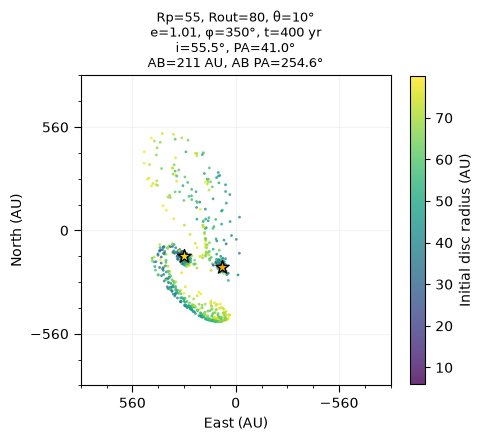

In [23]:
# Best model from global search
# logL=-0.0026 | Rp=55, Rout=80, e=1.01, peri=200°, theta=10°, phi=350°, t=400 yr | AB=208.9 AU, PA=253.92°

best_model = run_model(r_peri=55, r_out=80, theta_disc_deg=10, phi_disc_deg=350, ecc=1.01,
    peri_direction_deg=200, t_final=400, n_disc=1000, n_snapshots=1, seed=0)

plot_models(best_model)